# Nhận diện xu hướng & lọc cổ phiếu VN (đa khung D / W / M)
Thay vì đoán giá đóng cửa ngày mai, pipeline mới làm 4 việc:

1. Đọc dữ liệu ngày của toàn thị trường từ file CSV, tự gộp thành tuần và tháng.
2. Tính **trạng thái xu hướng từng khung** theo đúng logic đã thống nhất, cộng **kênh hồi quy** (thay cho đường song song kẻ tay) và các feature giảm nhiễu.
3. Gắn **nhãn độc lập với quy tắc**: sau `H` phiên giá tăng / giảm / đi ngang.
4. Kiểm tra quy tắc có thật sự có lợi thế không, train model, rồi chạy screener cả danh sách mã.

**Giả định tạm thời (sửa ở phần cấu hình / hàm tương ứng nếu sai):**
- Đk 1.1 dùng khung **D1** thay vì H1.
- Khung ngày: `close > MA10` mà `MA10 < MA50` (trường hợp logic cũ chưa nói) được xếp là **tăng** (giá dẫn dắt), giống quy tắc "các trường hợp còn lại → tăng" ở khung tuần.
- Khung tháng dùng cùng hàm với khung tuần (MACD vs Signal, trạng thái hiện tại, giá và MA thắng MACD).
- "Gãy MA50" = đóng cửa dưới MA50 **1 phiên**, kèm nhãn gãy mạnh / yếu (khối lượng, % lệch).
- Dữ liệu cần là **giá đã điều chỉnh** (chia tách, cổ phiếu thưởng, cổ tức bằng cổ phiếu), nếu không MA, kênh và nhãn sẽ sai.
- Tín hiệu khung tuần / tháng chỉ dùng **nến đã đóng** (không nhìn trước tương lai), trừ dòng cuối cùng khi quét hiện tại, lúc đó dùng nến đang chạy.

# Import

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings('ignore')

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Cấu hình

In [4]:
CSV_PATH    = '/content/drive/MyDrive/AI-Based Stock Ranking System for the Vietnamese Stock Market/data/data_full_market.csv'   # cột: date, symbol, open, high, low, close, volume, exchange
PRICE_SCALE = 1000                     # giá trong file là đồng -> chia 1000 ra nghìn đồng (đã là nghìn đồng thì đặt 1)
MIN_BARS    = 1500                     # bỏ mã có ít hơn ngần này phiên (khung tháng cần nhiều lịch sử)
MIN_VALUE   = 1.0                      # bỏ mã có giá trị giao dịch trung vị 1 năm gần nhất < ngần này (tỷ đồng/phiên)
MAX_SYMBOLS = None                     # đặt 50 để chạy thử nhanh, None = dùng tất cả

H          = 20            # nhìn về phía trước H phiên để gán nhãn
UP_T       = 0.05          # sau H phiên: >= +5% là Tăng, <= -5% là Giảm, còn lại Đi ngang
TRAIN_FRAC = 0.7           # chia theo thời gian, KHÔNG xáo trộn

CHAN_N     = {'D': 120, 'W': 52, 'M': 60}   # số nến để vẽ kênh hồi quy mỗi khung
CHAN_K     = 2.0                              # độ rộng kênh = hồi quy +- K độ lệch chuẩn

SAVE_DIR   = '/content/drive/MyDrive/AI-Based Stock Ranking System for the Vietnamese Stock Market/models'    # trên Colab có thể đổi sang đường dẫn Google Drive

# Data

Đọc CSV, làm sạch, tách theo mã. File chỉ cần dữ liệu **ngày**; tuần và tháng được gộp từ đó.

In [5]:
raw = pd.read_csv(CSV_PATH, usecols=['date', 'symbol', 'open', 'high', 'low', 'close', 'volume', 'exchange'])
raw['date'] = pd.to_datetime(raw['date']).dt.normalize()
for col in ['open', 'high', 'low', 'close']:
    raw[col] = raw[col] / PRICE_SCALE                    # đơn vị: nghìn đồng
print('Số dòng thô:', len(raw), '| số mã:', raw['symbol'].nunique())

# làm sạch cơ bản
raw = raw[(raw['close'] > 0) & (raw['low'] > 0) & (raw['high'] >= raw['low']) & (raw['volume'] > 0)]
raw = raw.drop_duplicates(['symbol', 'date'], keep='last').sort_values(['symbol', 'date'])

_groups, EXCH = {}, {}
dropped_short = dropped_illiquid = 0
for sym, g in raw.groupby('symbol'):
    if len(g) < MIN_BARS:
        dropped_short += 1
        continue
    # giá trị giao dịch (tỷ đồng/phiên) = close(nghìn đồng) * volume * 1000 / 1e9
    value = (g['close'] * g['volume'] * 1000 / 1e9).tail(250).median()
    if value < MIN_VALUE:
        dropped_illiquid += 1
        continue
    _groups[sym] = g.set_index('date')[['open', 'high', 'low', 'close', 'volume']].rename_axis('time')
    EXCH[sym] = g['exchange'].iloc[-1]

TICKERS = list(_groups)[:MAX_SYMBOLS]
print(f'Dùng {len(TICKERS)} mã | bỏ {dropped_short} mã quá ngắn, {dropped_illiquid} mã thanh khoản thấp')
print(pd.Series({t: EXCH[t] for t in TICKERS}).value_counts().to_dict())

def get_daily(ticker):
    return _groups[ticker]

def resample_ohlcv(df, rule):
    """Gộp nến ngày -> tuần / tháng. Nhãn thời gian = NGÀY GIAO DỊCH CUỐI THỰC TẾ của kỳ,
    nên khi gắn ngược về khung ngày sẽ không bị nhìn trước tương lai."""
    agg = {'open': 'first', 'high': 'max', 'low': 'min', 'close': 'last', 'volume': 'sum'}
    out = df.resample(rule).agg(agg)
    last_day = pd.Series(df.index, index=df.index).resample(rule).max()
    ok = out['close'].notna()
    out = out[ok]
    out.index = pd.DatetimeIndex(last_day[ok].values, name='time').astype('datetime64[ns]')
    return out

get_daily(TICKERS[0]).tail()

Số dòng thô: 2464141 | số mã: 1274
Dùng 265 mã | bỏ 552 mã quá ngắn, 457 mã thanh khoản thấp
{'HOSE': 185, 'HNX': 44, 'UPCOM': 36}


,open,high,low,close,volume
time,,,,,
2026-05-04,7.37,7.60,7.37,7.48,3185359.0
2026-05-05,7.49,7.50,7.30,7.37,701994.0
2026-05-06,7.42,7.52,7.33,7.45,1390877.0
2026-05-07,7.45,7.52,7.30,7.30,1339276.0
2026-05-08,7.30,7.36,7.16,7.19,856618.0


# Chỉ báo

Gồm MA, MACD (12, 26, 9), RSI 14 (Wilder), ADX 14 và kênh hồi quy tuyến tính trên log giá.

In [6]:
def sma(s, n): return s.rolling(n).mean()
def ema(s, n): return s.ewm(span=n, adjust=False).mean()

def macd(close, fast=12, slow=26, sig=9):
    line = ema(close, fast) - ema(close, slow)
    signal = ema(line, sig)
    return line, signal, line - signal

def rsi(close, n=14):
    d = close.diff()
    au = d.clip(lower=0).ewm(alpha=1 / n, adjust=False, min_periods=n).mean()
    ad = (-d.clip(upper=0)).ewm(alpha=1 / n, adjust=False, min_periods=n).mean()
    return 100 - 100 / (1 + au / ad)

def adx(df, n=14):
    up, dn = df['high'].diff(), -df['low'].diff()
    plus  = pd.Series(np.where((up > dn) & (up > 0), up, 0.0), index=df.index)
    minus = pd.Series(np.where((dn > up) & (dn > 0), dn, 0.0), index=df.index)
    tr = pd.concat([df['high'] - df['low'],
                    (df['high'] - df['close'].shift()).abs(),
                    (df['low'] - df['close'].shift()).abs()], axis=1).max(axis=1)
    w = dict(alpha=1 / n, adjust=False, min_periods=n)
    atr = tr.ewm(**w).mean()
    pdi = 100 * plus.ewm(**w).mean() / atr
    mdi = 100 * minus.ewm(**w).mean() / atr
    dx = 100 * (pdi - mdi).abs() / (pdi + mdi)
    return dx.ewm(**w).mean()

def reg_channel(close, n, k=CHAN_K):
    """Kênh hồi quy trên log giá, tính trong n nến gần nhất (chỉ dùng quá khứ + nến hiện tại).
    chan_pos: 0 = sát hỗ trợ (cạnh dưới), 1 = sát kháng cự (cạnh trên), <0 hoặc >1 = ra ngoài kênh.
    chan_slope: % thay đổi theo đường hồi quy trong cả cửa sổ (log). chan_width: độ rộng kênh (log)."""
    cols = ['chan_pos', 'chan_slope', 'chan_width', 'chan_out']
    res = np.full((len(close), 4), np.nan)
    y = np.log(close.values.astype(float))
    if len(y) >= n:
        w = sliding_window_view(y, n)
        x = np.arange(n) - (n - 1) / 2
        slope = (w * x).sum(1) / (x ** 2).sum()
        mean = w.mean(1)
        fit = mean[:, None] + slope[:, None] * x
        sd = np.sqrt(((w - fit) ** 2).mean(1))
        sd = np.where(sd == 0, np.nan, sd)
        last_fit = mean + slope * x[-1]
        pos = (w[:, -1] - (last_fit - k * sd)) / (2 * k * sd)
        res[n - 1:, 0] = pos
        res[n - 1:, 1] = slope * n
        res[n - 1:, 2] = 2 * k * sd
        res[n - 1:, 3] = np.where(pos < 0, -1, np.where(pos > 1, 1, 0))
        res[n - 1:, 3] = np.where(np.isnan(pos), np.nan, res[n - 1:, 3])
    return pd.DataFrame(res, index=close.index, columns=cols)

def rsi_two_bottoms(df, r, k=3, max_age=60, min_gap=5):
    """RSI tạo 2 đáy, đáy sau cao hơn. Đáy cần k nến bên phải để xác nhận, và chỉ được dùng
    SAU khi đã xác nhận (không nhìn trước). rsi_div = phân kỳ dương (giá đáy sau thấp hơn/bằng)."""
    n = len(df)
    is_piv = (r == r.rolling(2 * k + 1, center=True).min())
    pos = pd.Series(np.arange(n, dtype=float), index=df.index)
    conf = pd.DataFrame({'rsi': r.where(is_piv), 'low': df['low'].where(is_piv),
                         'pos': pos.where(is_piv)}).shift(k)
    ev = conf.dropna()
    last = ev.reindex(df.index).ffill()
    prev = ev.shift(1).reindex(df.index).ffill()
    age = pos - last['pos']
    spacing = last['pos'] - prev['pos']
    hl = ((last['rsi'] > prev['rsi']) & (last['rsi'] < 50) & (age <= max_age)
          & (spacing >= min_gap) & (spacing <= max_age))
    div = hl & (last['low'] <= prev['low'])
    return pd.DataFrame({'rsi_hl': hl.astype(float), 'rsi_div': div.astype(float),
                         'rsi_piv_diff': last['rsi'] - prev['rsi'], 'rsi_piv_age': age}, index=df.index)

# Trạng thái xu hướng từng khung

**Khung ngày** (5 mức, từ logic MA10 / MA50):

| state | điều kiện | ý nghĩa |
|---|---|---|
| 2 | close > MA10 > MA50 | tăng mạnh |
| 1 | close > MA10, MA10 <= MA50 | giá dẫn dắt, đang đảo chiều (giả định) |
| 0 | close <= MA10, MA10 > MA50, close >= MA50 | điều chỉnh, đang test MA10/MA50, chưa gãy |
| -1 | close < MA10, MA10 > MA50, close < MA50 | **gãy MA50** |
| -2 | close < MA10, MA10 <= MA50 | yếu, xu hướng giảm |

Hướng (`dir`) = 1 nếu state >= 1, ngược lại 0.

**Khung tuần / tháng:** MACD < Signal → giảm. MACD > Signal nhưng giá dưới MA10, MA50 và MA10 < MA50 → vẫn giảm. Còn lại → tăng.

In [7]:
def daily_state(close, ma10, ma50):
    s = pd.Series(np.nan, index=close.index)
    up10, ma_up = close > ma10, ma10 > ma50
    s[up10 & ma_up] = 2
    s[up10 & ~ma_up] = 1
    s[~up10 & ma_up & (close >= ma50)] = 0
    s[~up10 & ma_up & (close < ma50)] = -1
    s[~up10 & ~ma_up] = -2
    s[ma50.isna()] = np.nan
    return s

def htf_dir(close, ma10, ma50, m, sg):
    weak = (close < ma10) & (close < ma50) & (ma10 < ma50)
    d = ((m > sg) & ~weak).astype(float)
    d.iloc[:35] = np.nan          # MACD chưa đủ dữ liệu ổn định
    return d

def tf_features(df, n_chan):
    """Feature chung cho mọi khung (D, W, M)."""
    c = df['close']
    ma10, ma50 = sma(c, 10), sma(c, 50)
    m, sg, h = macd(c)
    f = pd.DataFrame(index=df.index)
    f['dir'] = htf_dir(c, ma10, ma50, m, sg)
    f['macd_hist'] = h / c
    f['dist_ma10'] = c / ma10 - 1
    f['dist_ma50'] = c / ma50 - 1
    f['ma_gap'] = ma10 / ma50 - 1
    f['rsi'] = rsi(c)
    return pd.concat([f, reg_channel(c, n_chan)], axis=1)

def daily_features(df):
    f = tf_features(df, CHAN_N['D'])
    c, v = df['close'], df['volume']
    ma10, ma50 = sma(c, 10), sma(c, 50)
    st = daily_state(c, ma10, ma50)
    f['state'] = st
    f['dir'] = (st >= 1).astype(float).where(st.notna())
    # --- các feature giảm nhiễu ---
    f['adx'] = adx(df)                                        # < 20: đi ngang, tín hiệu cắt MA dễ nhiễu
    f['vol_ratio'] = v / sma(v, 20)                           # khối lượng so với TB 20 phiên
    f['ma_gap_small'] = (f['ma_gap'].abs() < 0.02).astype(float)   # MA10 sát MA50: chưa rõ xu hướng
    f['break50'] = (st == -1).astype(float)                   # gãy MA50 (1 phiên)
    f['break50_strong'] = ((st == -1) & ((f['vol_ratio'] > 1) | (f['dist_ma50'] < -0.02))).astype(float)
    f['below50_3d'] = (c < ma50).astype(float).rolling(3).sum()   # xác nhận gãy qua 3 phiên
    f['ret_5'] = c.pct_change(5)
    f['ret_20'] = c.pct_change(20)
    return pd.concat([f, rsi_two_bottoms(df, f['rsi'])], axis=1)

# Ghép 3 khung & phân loại trạng thái thị trường

Feature tuần / tháng được gắn vào từng dòng ngày bằng `merge_asof` theo ngày giao dịch cuối của kỳ, nên ngày nào cũng chỉ thấy nến tuần / tháng **đã đóng**.

Bảng 8 tổ hợp (tháng, tuần, ngày) đã duyệt được mã hóa thành cột `regime` để đọc bằng mắt và để kiểm tra lợi thế.

In [8]:
REGIME = {
    (1, 1, 1): 'Tăng mạnh',
    (1, 1, 0): 'Điều chỉnh trong tăng',
    (1, 0, 1): 'Nhịp hồi sau điều chỉnh',
    (1, 0, 0): 'Điều chỉnh sâu',
    (0, 1, 1): 'Hồi mạnh / có thể đảo chiều',
    (0, 1, 0): 'Nhịp nghỉ trong hồi (yếu)',
    (0, 0, 1): 'Hồi kỹ thuật dạng V trong xu hướng giảm',
    (0, 0, 0): 'Giảm mạnh',
}

def attach_htf(base, htf):
    left = base[[]].reset_index()
    right = htf.reset_index()
    left['time'] = left['time'].astype('datetime64[ns]')
    right['time'] = right['time'].astype('datetime64[ns]')
    merged = pd.merge_asof(left, right, on='time', direction='backward').set_index('time')
    return merged

REGIME_BY_CODE = {m * 4 + w * 2 + d: name for (m, w, d), name in REGIME.items()}

def label_regime(f):
    """Vector hóa: gán tên trạng thái cho toàn bộ bảng cùng lúc."""
    name = f['combo'].map(REGIME_BY_CODE)
    adj = (f['combo'] == 6)                               # Đk 2.2: tháng tăng, tuần tăng, ngày xuống
    name = name.where(~(adj & (f['state_d'] == 0)), name + ' (giữ MA50, chờ tăng lại)')
    name = name.where(~(adj & (f['state_d'] == -1)), name + ' (GÃY MA50, cảnh báo)')
    return name

def build_features(df_daily):
    d = daily_features(df_daily).add_suffix('_d')
    w = tf_features(resample_ohlcv(df_daily, 'W-FRI'), CHAN_N['W']).add_suffix('_w')
    m = tf_features(resample_ohlcv(df_daily, 'MS'), CHAN_N['M']).add_suffix('_m')
    out = pd.concat([d, attach_htf(d, w), attach_htf(d, m)], axis=1)
    out['combo'] = out['dir_m'] * 4 + out['dir_w'] * 2 + out['dir_d']
    out['regime'] = label_regime(out)
    out['sideways'] = (out['adx_d'] < 20).astype(float).where(out['adx_d'].notna())
    return out

# Nhãn (đáp án) độc lập với quy tắc

Nếu dùng chính quy tắc để gán nhãn thì model chỉ học thuộc lại quy tắc. Ở đây nhãn lấy từ **diễn biến giá thực tế** sau `H` phiên:

- `2` = Tăng (lợi nhuận >= +`UP_T`), `0` = Giảm (<= -`UP_T`), `1` = Đi ngang.
- `fwd_mdd` = mức sụt sâu nhất (theo giá thấp nhất) trong `H` phiên tới, dùng để đánh giá rủi ro.

In [9]:
def add_labels(f, df):
    c, lo = df['close'], df['low']
    fwd = c.shift(-H) / c - 1
    # đáy thấp nhất trong các phiên t+1 .. t+H
    mdd = lo.iloc[::-1].rolling(H).min().iloc[::-1].shift(-1) / c - 1
    lab = pd.Series(1.0, index=df.index)
    lab[fwd >= UP_T] = 2
    lab[fwd <= -UP_T] = 0
    lab[fwd.isna()] = np.nan
    f = f.copy()
    f['fwd_ret'], f['fwd_mdd'], f['label'] = fwd, mdd, lab
    return f

def build_all(tickers):
    frames = []
    for t in tickers:
        try:
            df = get_daily(t)
        except Exception as e:
            print('Bỏ qua', t, '-', e)
            continue
        f = add_labels(build_features(df), df)
        f['symbol'], f['exchange'], f['close'] = t, EXCH[t], df['close']
        num = f.select_dtypes('number').columns
        f[num] = f[num].astype('float32')                 # tiết kiệm RAM khi chạy cả thị trường
        frames.append(f)
    return pd.concat(frames)

data = build_all(TICKERS)
FEATURES = [c for c in data.columns if c.endswith(('_d', '_w', '_m'))] + ['combo', 'sideways']
data = data.dropna(subset=['dir_d', 'dir_w', 'dir_m'])
print(data.shape, '| số feature:', len(FEATURES))
data[['symbol', 'close', 'regime', 'chan_pos_m', 'label']].tail()

(617737, 52) | số feature: 45


,symbol,close,regime,chan_pos_m,label
time,,,,,
2026-05-04,YEG,10.00,Giảm mạnh,0.383968,NaN
2026-05-05,YEG,9.96,Giảm mạnh,0.383968,NaN
2026-05-06,YEG,9.99,Giảm mạnh,0.383968,NaN
2026-05-07,YEG,9.97,Giảm mạnh,0.383968,NaN
2026-05-08,YEG,9.91,Giảm mạnh,0.369720,NaN


# Kiểm tra quy tắc có lợi thế không (chưa cần model)

Quy tắc không được "học" từ dữ liệu nên bảng này đo trên toàn bộ dữ liệu. Cột `p_up`, `p_down` là xác suất thực tế sau `H` phiên. Nếu các trạng thái "tăng" không cho `mean_ret` / `p_up` cao hơn trạng thái "giảm" thì quy tắc cần chỉnh trước khi train.

Nền chung (0=Giảm, 1=Ngang, 2=Tăng): {0.0: 0.265, 1.0: 0.428, 2.0: 0.307} | lợi nhuận TB: 0.0147


,n,mean_ret,win,p_up,p_down,med_mdd
regime,,,,,,
Tăng mạnh,84541,0.032,0.519,0.367,0.289,-0.069
"Điều chỉnh trong tăng (giữ MA50, chờ tăng lại)",46472,0.023,0.507,0.338,0.279,-0.069
"Điều chỉnh trong tăng (GÃY MA50, cảnh báo)",10282,0.023,0.514,0.329,0.263,-0.069
Điều chỉnh trong tăng,7519,0.017,0.509,0.315,0.257,-0.066
Hồi mạnh / có thể đảo chiều,71464,0.017,0.499,0.310,0.264,-0.058
Nhịp hồi sau điều chỉnh,66747,0.016,0.507,0.314,0.259,-0.057
Hồi kỹ thuật dạng V trong xu hướng giảm,79993,0.014,0.498,0.295,0.238,-0.053
Điều chỉnh sâu,80193,0.008,0.493,0.292,0.267,-0.063
Nhịp nghỉ trong hồi (yếu),47943,0.007,0.484,0.282,0.259,-0.056


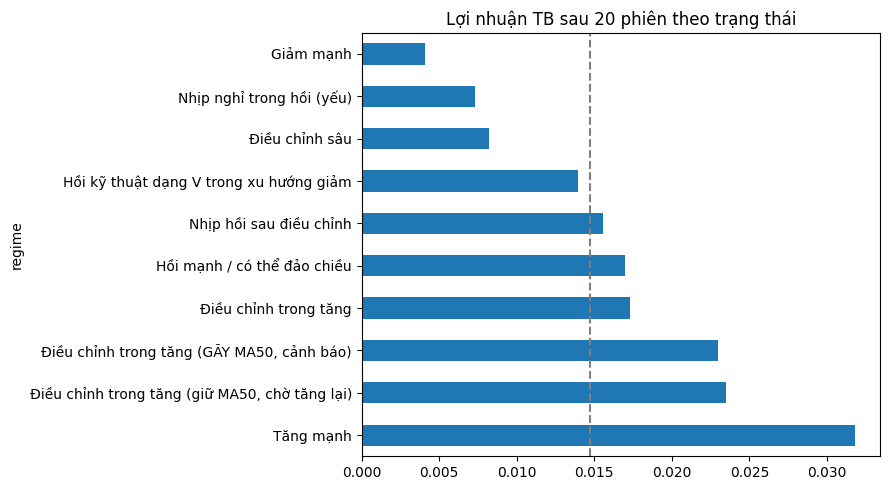

In [10]:
valid = data.dropna(subset=['label'])
base = valid['label'].value_counts(normalize=True).sort_index()
print('Nền chung (0=Giảm, 1=Ngang, 2=Tăng):', base.round(3).to_dict(), '| lợi nhuận TB:', round(valid['fwd_ret'].mean(), 4))

summary = (valid.groupby('regime')
    .agg(n=('fwd_ret', 'size'),
         mean_ret=('fwd_ret', 'mean'),
         win=('fwd_ret', lambda s: (s > 0).mean()),
         p_up=('label', lambda s: (s == 2).mean()),
         p_down=('label', lambda s: (s == 0).mean()),
         med_mdd=('fwd_mdd', 'median'))
    .sort_values('mean_ret', ascending=False))
display(summary.round(3))

summary['mean_ret'].plot.barh(figsize=(9, 5), title=f'Lợi nhuận TB sau {H} phiên theo trạng thái')
plt.axvline(valid['fwd_ret'].mean(), color='gray', ls='--')
plt.tight_layout(); plt.show()

**Kiểm tra giả thuyết "giảm nhưng đang ở vùng hỗ trợ" (như ANV tháng):** khi khung tháng giảm, giá nằm sát cạnh dưới kênh (`chan_pos_m` thấp) có hồi nhiều hơn không?

In [11]:
bucket = pd.cut(valid['chan_pos_m'], [-np.inf, 0, 0.25, 0.75, 1, np.inf],
                labels=['Lủng kênh', 'Sát hỗ trợ', 'Giữa kênh', 'Sát kháng cự', 'Vượt kênh'])
(valid.assign(chan_m=bucket)
      .groupby(['dir_m', 'chan_m'])
      .agg(n=('fwd_ret', 'size'), mean_ret=('fwd_ret', 'mean'),
           p_up=('label', lambda s: (s == 2).mean()), p_down=('label', lambda s: (s == 0).mean()))
      .round(3))

n  mean_ret   p_up  p_down
dir_m chan_m                                       
0.0   Lủng kênh      21277     0.026  0.358   0.243
      Sát hỗ trợ     85647     0.018  0.304   0.230
      Giữa kênh     148356     0.006  0.278   0.263
      Sát kháng cự    1978     0.023  0.312   0.260
      Vượt kênh         18    -0.091  0.167   0.556
1.0   Lủng kênh        130    -0.078  0.192   0.554
      Sát hỗ trợ      2363     0.008  0.298   0.209
      Giữa kênh     120087     0.014  0.302   0.258
      Sát kháng cự   66682     0.020  0.330   0.284
      Vượt kênh      37258     0.032  0.385   0.312

# Train model

Chia **theo thời gian** (không xáo trộn) và chừa khoảng trống `H` phiên giữa train và test, vì nhãn của những ngày cuối train đã "nhìn" vào giá của đầu test. Model dùng cây tăng cường (`HistGradientBoosting`), tự xử lý giá trị thiếu và không cần scale dữ liệu.

In [12]:
dates = np.sort(valid.index.unique())
cut = dates[int(len(dates) * TRAIN_FRAC)]
gap = pd.Timedelta(days=int(H * 1.5))

train = valid[valid.index < cut - gap]
test  = valid[valid.index >= cut]
print('Train:', train.index.min().date(), '->', train.index.max().date(), len(train))
print('Test :', test.index.min().date(), '->', test.index.max().date(), len(test))

model = HistGradientBoostingClassifier(
    max_depth=4, learning_rate=0.05, max_iter=300,
    l2_regularization=1.0, min_samples_leaf=50,
    class_weight='balanced', early_stopping=False, random_state=42)
model.fit(train[FEATURES], train['label'].astype(int))

Train: 2008-11-28 -> 2020-12-11 277346
Test : 2021-01-13 -> 2026-04-07 330542


HistGradientBoostingClassifier(class_weight='balanced', early_stopping=False,
                               l2_regularization=1.0, learning_rate=0.05,
                               max_depth=4, max_iter=300, min_samples_leaf=50,
                               random_state=42)

# Đánh giá

Điều quan trọng không phải độ chính xác, mà là: **nhóm mã model chấm xác suất tăng cao nhất có thật sự lãi hơn mức trung bình không?** Phần cuối dưới đây trả lời câu đó.

In [13]:
Xte, yte = test[FEATURES], test['label'].astype(int)
proba = model.predict_proba(Xte)                 # cột: 0=Giảm, 1=Ngang, 2=Tăng
pred = proba.argmax(1)

print(classification_report(yte, pred, target_names=['Giảm', 'Ngang', 'Tăng'], digits=3))
print(pd.DataFrame(confusion_matrix(yte, pred),
                   index=['thực Giảm', 'thực Ngang', 'thực Tăng'],
                   columns=['đoán Giảm', 'đoán Ngang', 'đoán Tăng']))

ev = test.assign(p_up=proba[:, 2], p_down=proba[:, 0])
ev['nhóm'] = pd.qcut(ev['p_up'], 5, labels=['1 (thấp nhất)', '2', '3', '4', '5 (cao nhất)'], duplicates='drop')
print('\nLợi nhuận thực tế sau', H, 'phiên theo nhóm xác suất Tăng (trên tập test):')
display(ev.groupby('nhóm').agg(n=('fwd_ret', 'size'), mean_ret=('fwd_ret', 'mean'),
                              win=('fwd_ret', lambda s: (s > 0).mean()),
                              p_up_thuc_te=('label', lambda s: (s == 2).mean()),
                              med_mdd=('fwd_mdd', 'median')).round(3))
print('Mức nền của tập test:', round(test['fwd_ret'].mean(), 4))

top = ev[ev['p_up'] >= ev['p_up'].quantile(0.8)]
print('\nTheo sàn: lợi nhuận TB sau', H, 'phiên, nền so với top 20% xác suất Tăng')
display(pd.DataFrame({'nền': ev.groupby('exchange')['fwd_ret'].mean(),
                      'top 20% P(tăng)': top.groupby('exchange')['fwd_ret'].mean(),
                      'n_top': top.groupby('exchange').size()}).round(4))

              precision    recall  f1-score   support

        Giảm      0.314     0.335     0.325     89428
       Ngang      0.567     0.426     0.487    138412
        Tăng      0.358     0.457     0.402    102702

    accuracy                          0.411    330542
   macro avg      0.413     0.406     0.404    330542
weighted avg      0.434     0.411     0.416    330542

            đoán Giảm  đoán Ngang  đoán Tăng
thực Giảm       29998       20514      38916
thực Ngang      34243       58976      45193
thực Tăng       31187       24547      46968

Lợi nhuận thực tế sau 20 phiên theo nhóm xác suất Tăng (trên tập test):


,n,mean_ret,win,p_up_thuc_te,med_mdd
nhóm,,,,,
1 (thấp nhất),66109,0.003,0.478,0.241,-0.047
2,66108,0.009,0.494,0.283,-0.053
3,66108,0.012,0.503,0.309,-0.060
4,66108,0.019,0.516,0.344,-0.067
5 (cao nhất),66109,0.022,0.525,0.377,-0.080


Mức nền của tập test: 0.0131

Theo sàn: lợi nhuận TB sau 20 phiên, nền so với top 20% xác suất Tăng


,nền,top 20% P(tăng),n_top
exchange,,,
HNX,0.0179,0.0337,13402
HOSE,0.0125,0.0192,44013
UPCOM,0.0105,0.0192,8694


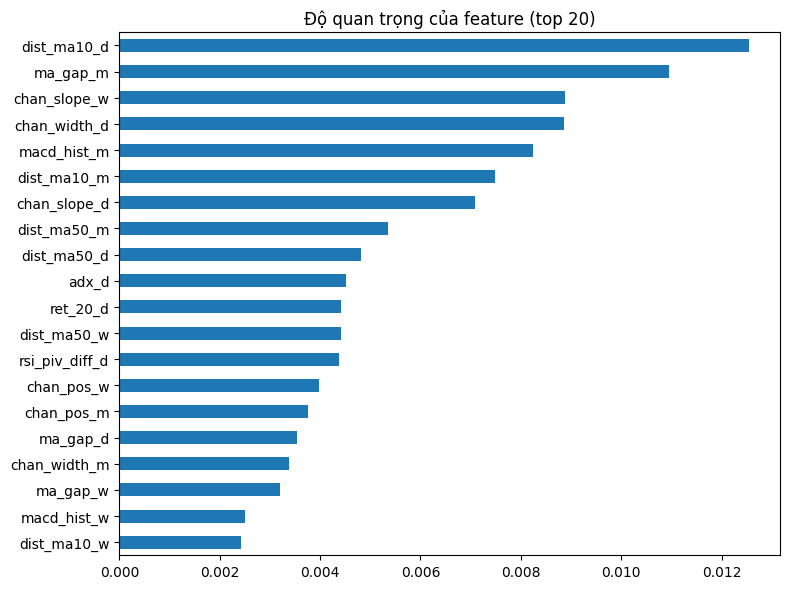

In [14]:
# Feature nào đóng góp thật sự (đo trên tập test)
sub = test.sample(min(3000, len(test)), random_state=0)
imp = permutation_importance(model, sub[FEATURES], sub['label'].astype(int),
                             n_repeats=5, scoring='balanced_accuracy', random_state=0)
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=False)
imp.head(20).iloc[::-1].plot.barh(figsize=(8, 6), title='Độ quan trọng của feature (top 20)')
plt.tight_layout(); plt.show()

# Lưu model

In [15]:
os.makedirs(SAVE_DIR, exist_ok=True)
save_path = os.path.join(SAVE_DIR, 'trend_model_v2.joblib')
joblib.dump({'model': model, 'features': FEATURES, 'H': H, 'UP_T': UP_T}, save_path)
print('Đã lưu:', save_path)

Đã lưu: /content/drive/MyDrive/AI-Based Stock Ranking System for the Vietnamese Stock Market/models/trend_model_v2.joblib


# Screener: quét danh sách mã

Dùng dữ liệu mới nhất trong file, tính trạng thái 3 khung + vị trí kênh + xác suất của model. Ở dòng cuối, nến tuần / tháng đang chạy được dùng luôn (giống cách bạn nhìn biểu đồ), nên nến tháng đang dở có thể đổi tín hiệu trước khi đóng. Muốn dữ liệu mới thì cập nhật file CSV rồi chạy lại cell Data.

In [16]:
def screen(tickers, model=model):
    rows = []
    for t in tickers:
        try:
            df = get_daily(t)
        except Exception as e:
            print('Bỏ qua', t, '-', e)
            continue
        f = build_features(df)
        last = f.iloc[-1]
        p = model.predict_proba(f[FEATURES].iloc[[-1]])[0]
        rows.append({
            'mã': t, 'sàn': EXCH.get(t), 'ngày': f.index[-1].date(), 'giá': round(df['close'].iloc[-1], 2),
            'trạng thái': last['regime'],
            'D': last['dir_d'], 'W': last['dir_w'], 'M': last['dir_m'],
            'kênh D': round(last['chan_pos_d'], 2), 'kênh W': round(last['chan_pos_w'], 2),
            'kênh M': round(last['chan_pos_m'], 2),
            'RSI D': round(last['rsi_d'], 1), 'RSI 2 đáy': bool(last['rsi_hl_d']),
            'phân kỳ': bool(last['rsi_div_d']), 'ADX': round(last['adx_d'], 1),
            'gãy MA50': bool(last['break50_strong_d']),
            'P(giảm)': round(p[0], 3), 'P(ngang)': round(p[1], 3), 'P(tăng)': round(p[2], 3)})
    return pd.DataFrame(rows).sort_values('P(tăng)', ascending=False).reset_index(drop=True)

result = screen(TICKERS[:100])   # quét thử 100 mã; bỏ [:100] để quét hết
result

,mã,sàn,ngày,giá,trạng thái,D,W,M,kênh D,kênh W,kênh M,RSI D,RSI 2 đáy,phân kỳ,ADX,gãy MA50,P(giảm),P(ngang),P(tăng)
0,GKM,HNX,2026-05-08,1.60,Giảm mạnh,0.0,0.0,0.0,0.16,0.61,0.26,29.1,False,False,51.3,False,0.147,0.130,0.723
1,CEN,UPCOM,2026-05-08,1.60,Giảm mạnh,0.0,0.0,0.0,0.43,0.21,0.62,31.7,False,False,32.5,False,0.157,0.155,0.688
2,AMV,HNX,2026-05-08,1.60,Giảm mạnh,0.0,0.0,0.0,0.56,0.62,0.42,38.6,False,False,19.3,False,0.197,0.207,0.596
3,DGC,HOSE,2026-05-08,52.20,Giảm mạnh,0.0,0.0,0.0,0.56,0.26,-0.02,42.3,False,False,12.2,False,0.213,0.194,0.593
4,HDC,HOSE,2026-05-08,18.55,Giảm mạnh,0.0,0.0,0.0,0.90,0.36,0.38,47.0,True,False,11.4,False,0.212,0.220,0.568
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,CTF,HOSE,2026-05-08,18.25,Giảm mạnh,0.0,0.0,0.0,0.47,0.47,0.18,45.6,True,False,23.7,False,0.276,0.542,0.182
96,CLX,UPCOM,2026-05-08,14.80,Giảm mạnh,0.0,0.0,0.0,0.36,0.19,0.56,40.8,True,True,14.8,False,0.276,0.550,0.174
97,HHS,HOSE,2026-05-08,12.95,Nhịp nghỉ trong hồi (yếu),0.0,1.0,0.0,0.72,0.63,0.49,48.8,False,False,14.2,False,0.557,0.287,0.156
98,BSI,HOSE,2026-05-08,34.95,Giảm mạnh,0.0,0.0,0.0,0.48,0.40,0.19,44.0,False,False,11.5,False,0.568,0.282,0.151


**Cách đọc:** `D / W / M` = 1 là tăng, 0 là giảm. `kênh` = 0 là sát hỗ trợ, 1 là sát kháng cự, âm là đã lủng, trên 1 là đã vượt. Ví dụ ANV tháng: `M = 0` nhưng `kênh M` thấp thì là "giảm nhưng tại hỗ trợ". Hãy dùng kết quả screener cùng bảng kiểm tra lợi thế ở phía trên, đừng tin riêng cột xác suất.